In [227]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv("housing.csv")
print(df)

       longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0        -122.23     37.88                41.0        880.0           129.0   
1        -122.22     37.86                21.0       7099.0          1106.0   
2        -122.24     37.85                52.0       1467.0           190.0   
3        -122.25     37.85                52.0       1274.0           235.0   
4        -122.25     37.85                52.0       1627.0           280.0   
...          ...       ...                 ...          ...             ...   
20635    -121.09     39.48                25.0       1665.0           374.0   
20636    -121.21     39.49                18.0        697.0           150.0   
20637    -121.22     39.43                17.0       2254.0           485.0   
20638    -121.32     39.43                18.0       1860.0           409.0   
20639    -121.24     39.37                16.0       2785.0           616.0   

       population  households  median_income  media

In [228]:
print(df.isnull().sum())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [229]:
df["total_bedrooms"] = df["total_bedrooms"].fillna(df['total_bedrooms'].median())
print(df)

       longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0        -122.23     37.88                41.0        880.0           129.0   
1        -122.22     37.86                21.0       7099.0          1106.0   
2        -122.24     37.85                52.0       1467.0           190.0   
3        -122.25     37.85                52.0       1274.0           235.0   
4        -122.25     37.85                52.0       1627.0           280.0   
...          ...       ...                 ...          ...             ...   
20635    -121.09     39.48                25.0       1665.0           374.0   
20636    -121.21     39.49                18.0        697.0           150.0   
20637    -121.22     39.43                17.0       2254.0           485.0   
20638    -121.32     39.43                18.0       1860.0           409.0   
20639    -121.24     39.37                16.0       2785.0           616.0   

       population  households  median_income  media

In [230]:
print(df.isnull().sum())

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


In [231]:
print(df.duplicated().sum())

0


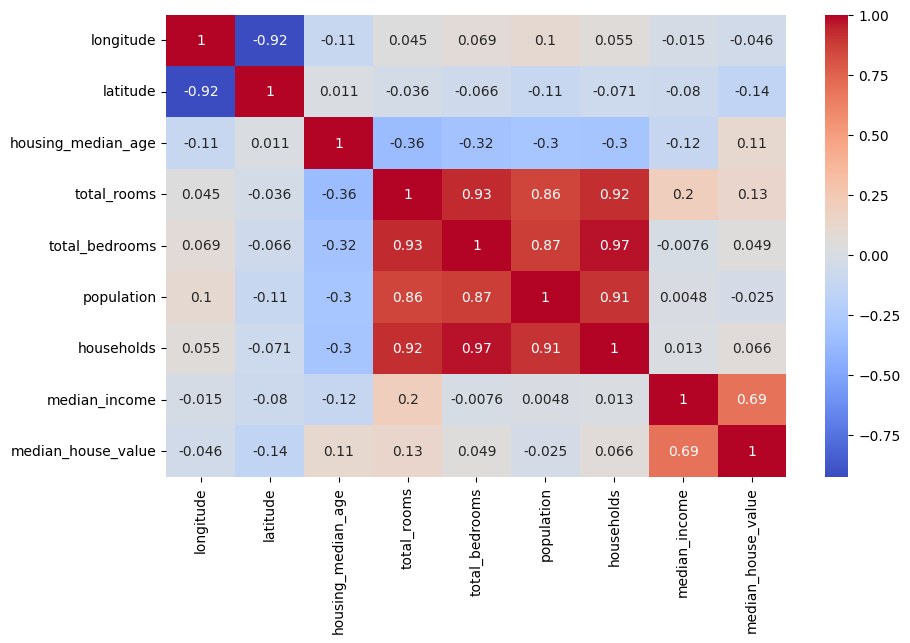

In [232]:
plt.figure(figsize=(10,6))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm')
plt.show()

In [233]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20640 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB
None


In [234]:
df = pd.get_dummies(df,columns=['ocean_proximity'],drop_first=True,dtype=int)

print(df.head())

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value  \
0       322.0       126.0         8.3252            452600.0   
1      2401.0      1138.0         8.3014            358500.0   
2       496.0       177.0         7.2574            352100.0   
3       558.0       219.0         5.6431            341300.0   
4       565.0       259.0         3.8462            342200.0   

   ocean_proximity_INLAND  ocean_proximity_ISLAND  ocean_proximity_NEAR BAY  \
0                       0                       0                         1   
1     

In [235]:
x = df.drop('median_house_value',axis=1)
y = df["median_house_value"]

In [236]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [237]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
ols_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

ols_model.fit(x_train, y_train)
ols_pred = ols_model.predict(x_test)
ols_rmse = np.sqrt(mean_squared_error(y_test, ols_pred))
ols_mae = mean_absolute_error(y_test, ols_pred)
ols_r2 = r2_score(y_test, ols_pred)

print("OLS Results")
print("RMSE:", ols_rmse)
print("MAE:", ols_mae)
print("R2 Score:", ols_r2)

OLS Results
RMSE: 70060.52184473518
MAE: 50670.73824097191
R2 Score: 0.6254240620553606


In [238]:
ols_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

ols_model.fit(x_train, y_train)

ols_pred = ols_model.predict(x_test)

print("OLS RMSE:", np.sqrt(mean_squared_error(y_test, ols_pred)))
print("OLS MAE:", mean_absolute_error(y_test, ols_pred))
print("OLS R2:", r2_score(y_test, ols_pred))

OLS RMSE: 70060.52184473518
OLS MAE: 50670.73824097191
OLS R2: 0.6254240620553606


In [239]:
from sklearn.model_selection import GridSearchCV
ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

ridge_grid = GridSearchCV(
    ridge_pipeline,
    {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

ridge_grid.fit(x_train, y_train)

ridge_pred = ridge_grid.predict(x_test)

print("Best Alpha:", ridge_grid.best_params_)
print("Ridge RMSE:", np.sqrt(mean_squared_error(y_test, ridge_pred)))
print("Ridge MAE:", mean_absolute_error(y_test, ridge_pred))
print("Ridge R2:", r2_score(y_test, ridge_pred))

Best Alpha: {'model__alpha': 10}
Ridge RMSE: 70031.30531058177
Ridge MAE: 50646.17065906169
Ridge R2: 0.6257364071110387


In [240]:
from sklearn.linear_model import Lasso
lasso_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=10000))
])

lasso_grid = GridSearchCV(
    lasso_pipeline,
    {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

lasso_grid.fit(x_train, y_train)

lasso_pred = lasso_grid.predict(x_test)

print("Best Alpha:", lasso_grid.best_params_)
print("Lasso RMSE:", np.sqrt(mean_squared_error(y_test, lasso_pred)))
print("Lasso MAE:", mean_absolute_error(y_test, lasso_pred))
print("Lasso R2:", r2_score(y_test, lasso_pred))

Best Alpha: {'model__alpha': 10}
Lasso RMSE: 70053.90421558928
Lasso MAE: 50664.70233178963
Lasso R2: 0.6254948205227593


In [241]:
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_r2 = r2_score(y_test, ridge_pred)

lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_pred))
lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_r2 = r2_score(y_test, lasso_pred)

In [242]:
results = pd.DataFrame({
    "Model": ["OLS", "Ridge", "Lasso"],
    "RMSE": [ols_rmse, ridge_rmse, lasso_rmse],
    "MAE": [ols_mae, ridge_mae, lasso_mae],
    "R2 Score": [ols_r2, ridge_r2, lasso_r2]
})

print(results.round(4))

   Model        RMSE         MAE  R2 Score
0    OLS  70060.5218  50670.7382    0.6254
1  Ridge  70031.3053  50646.1707    0.6257
2  Lasso  70053.9042  50664.7023    0.6255


Text(0, 0.5, 'Predicted House Value')

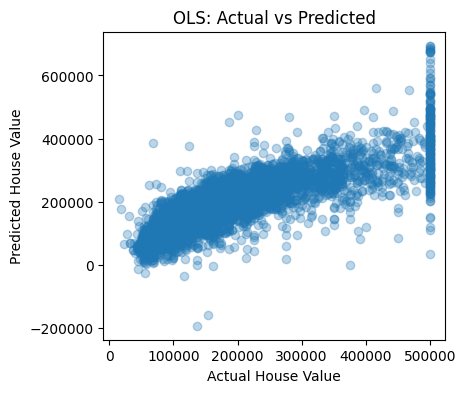

In [243]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.scatter(y_test, ols_pred, alpha=0.3)
plt.title("OLS: Actual vs Predicted")
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")

Text(0, 0.5, 'Predicted House Value')

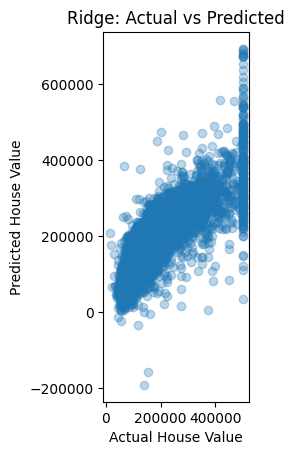

In [244]:
plt.subplot(1, 3, 2)
plt.scatter(y_test, ridge_pred, alpha=0.3)
plt.title("Ridge: Actual vs Predicted")
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")

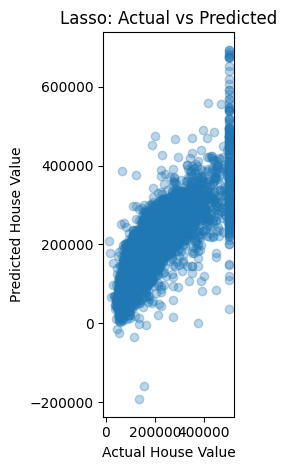

In [245]:
plt.subplot(1, 3, 3)
plt.scatter(y_test, lasso_pred, alpha=0.3)
plt.title("Lasso: Actual vs Predicted")
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")

plt.tight_layout()